In [1]:
from pathlib import Path
from joblib import load
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
import string

In [3]:
ROOT=Path("Datasets/PBMC/TDA_CellType_GEX/")
all_results={}

for celltype_dir in ROOT.iterdir():
    if not celltype_dir.is_dir(): continue
    celltype=celltype_dir.name
    print(f"Loading {celltype}")
    all_results[celltype]={}

    tda_path=celltype_dir/f"{celltype}_tda.joblib"
    tda=load(tda_path) if tda_path.exists() else None
    if tda is None: print(f"Missing: {tda_path}")

    for H in [0,1,2]:
        prefix=f"{celltype}_H{H}"
        objs={"tda":tda}

        for key in ["x_tda","results","marker_vs_random","marker_rank"]:
            path=celltype_dir/f"{prefix}_{key}.joblib"
            objs[key]=load(path) if path.exists() else None
            if objs[key] is None: print(f"Missing: {path}")

        all_results[celltype][f"H{H}"]=objs

Loading B


# Barplots

Plotting B


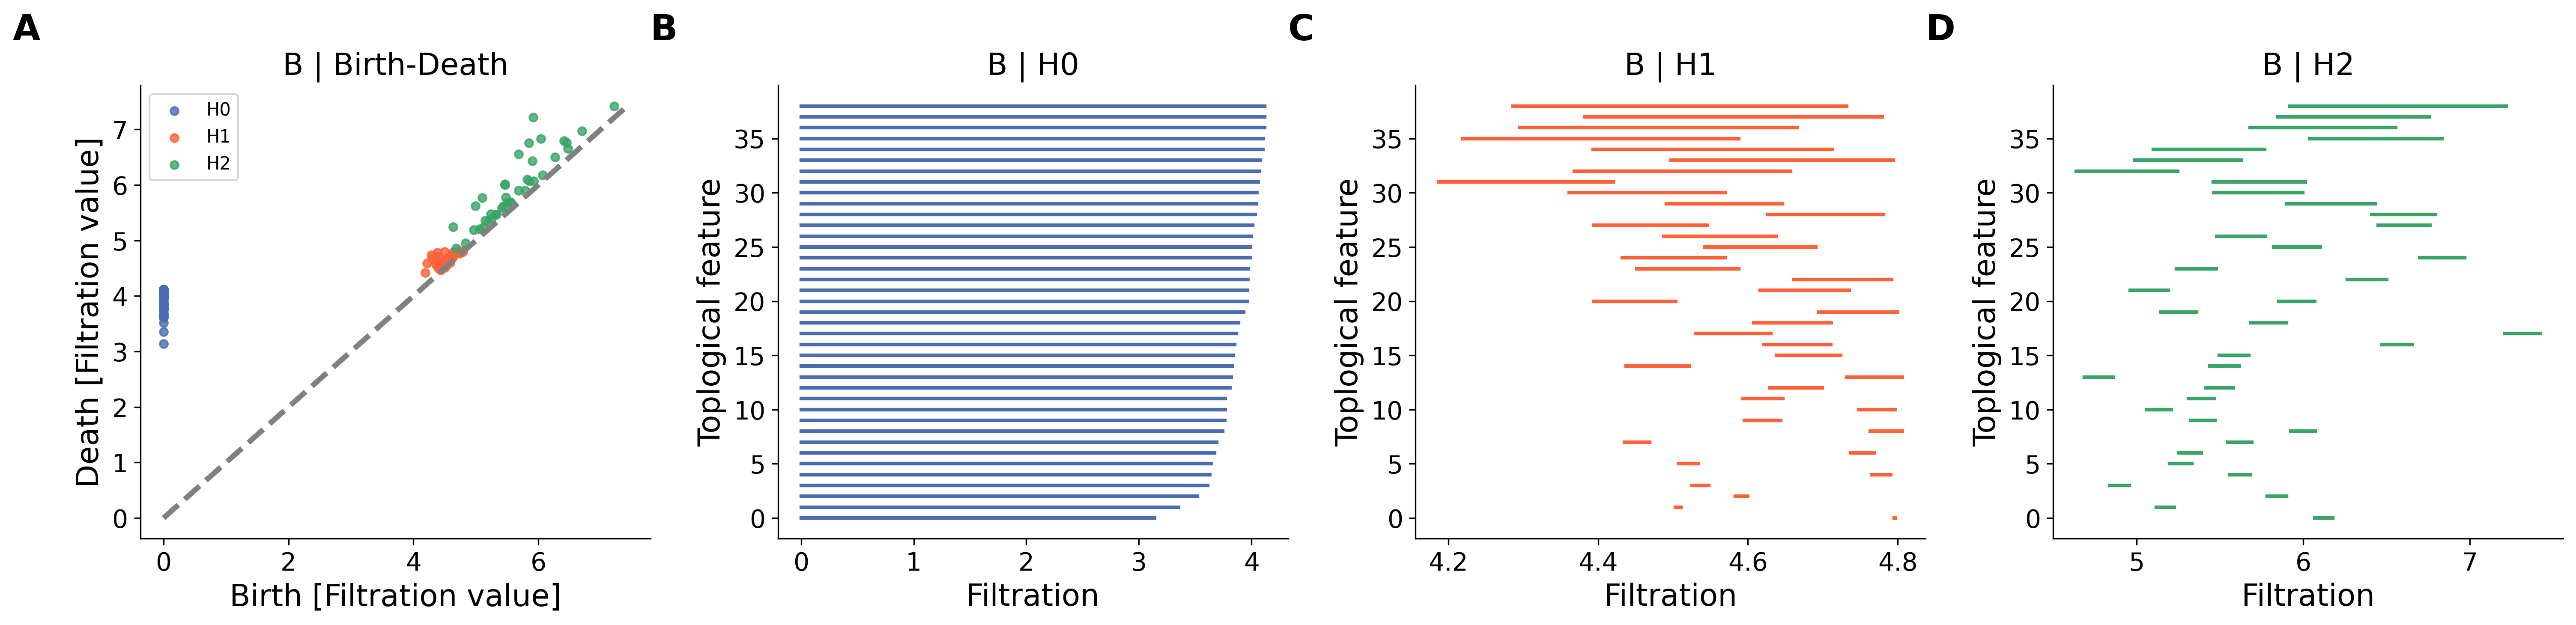

Plotting Monocytes


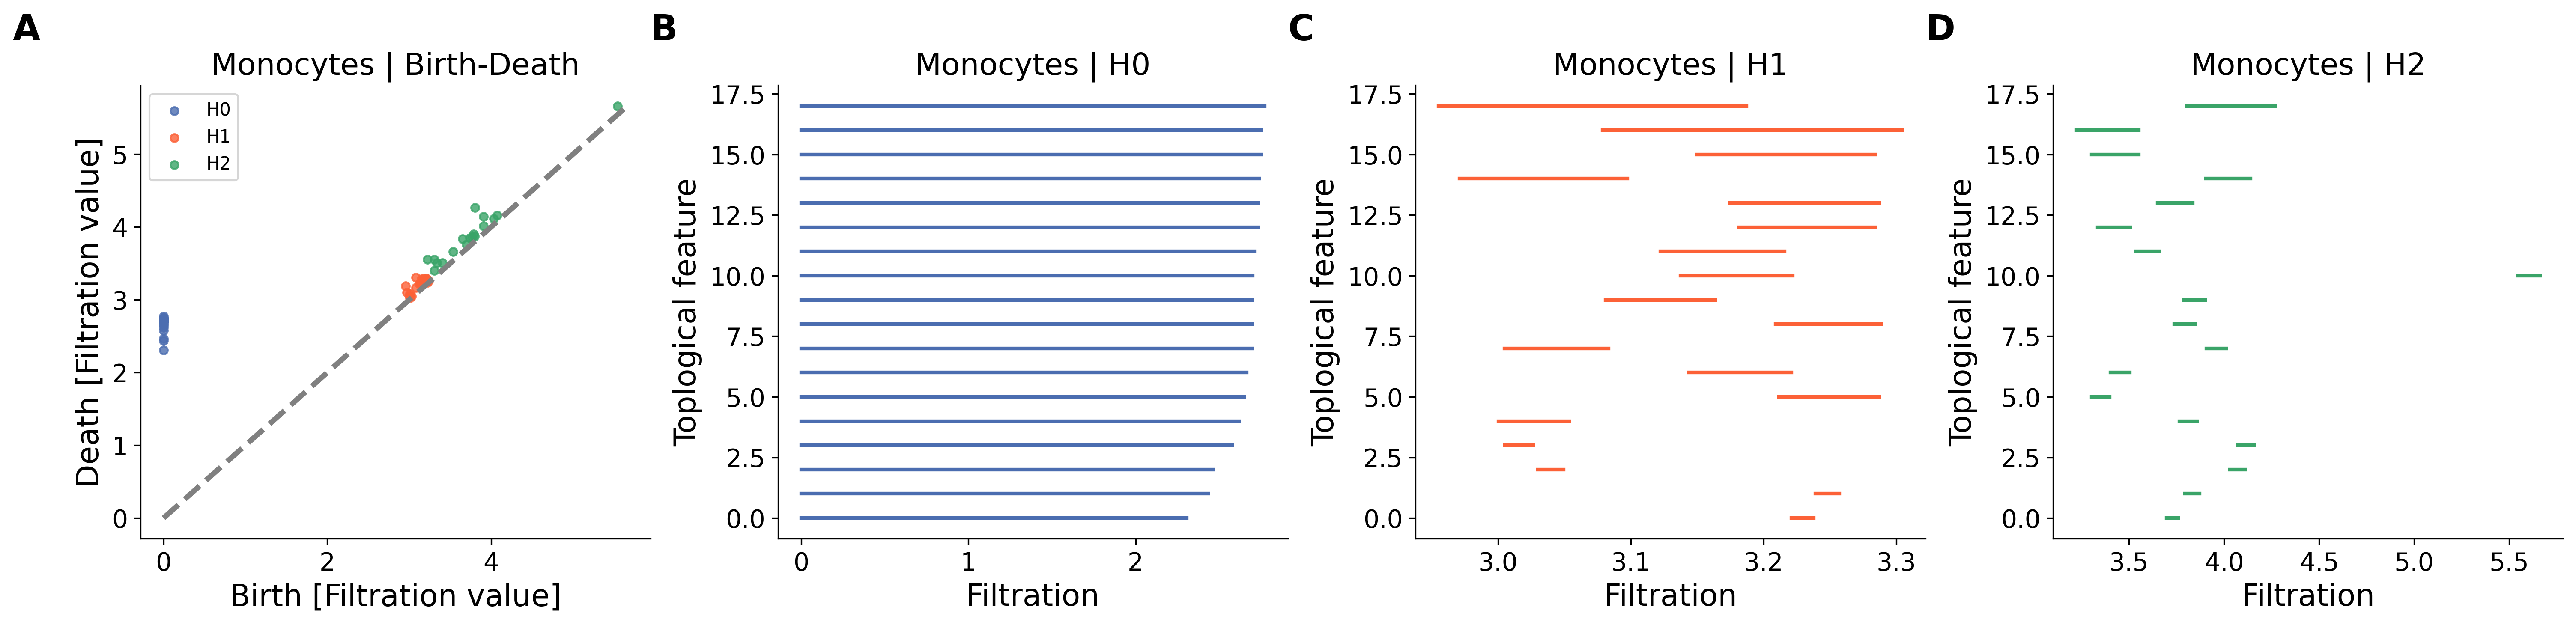

Plotting NK


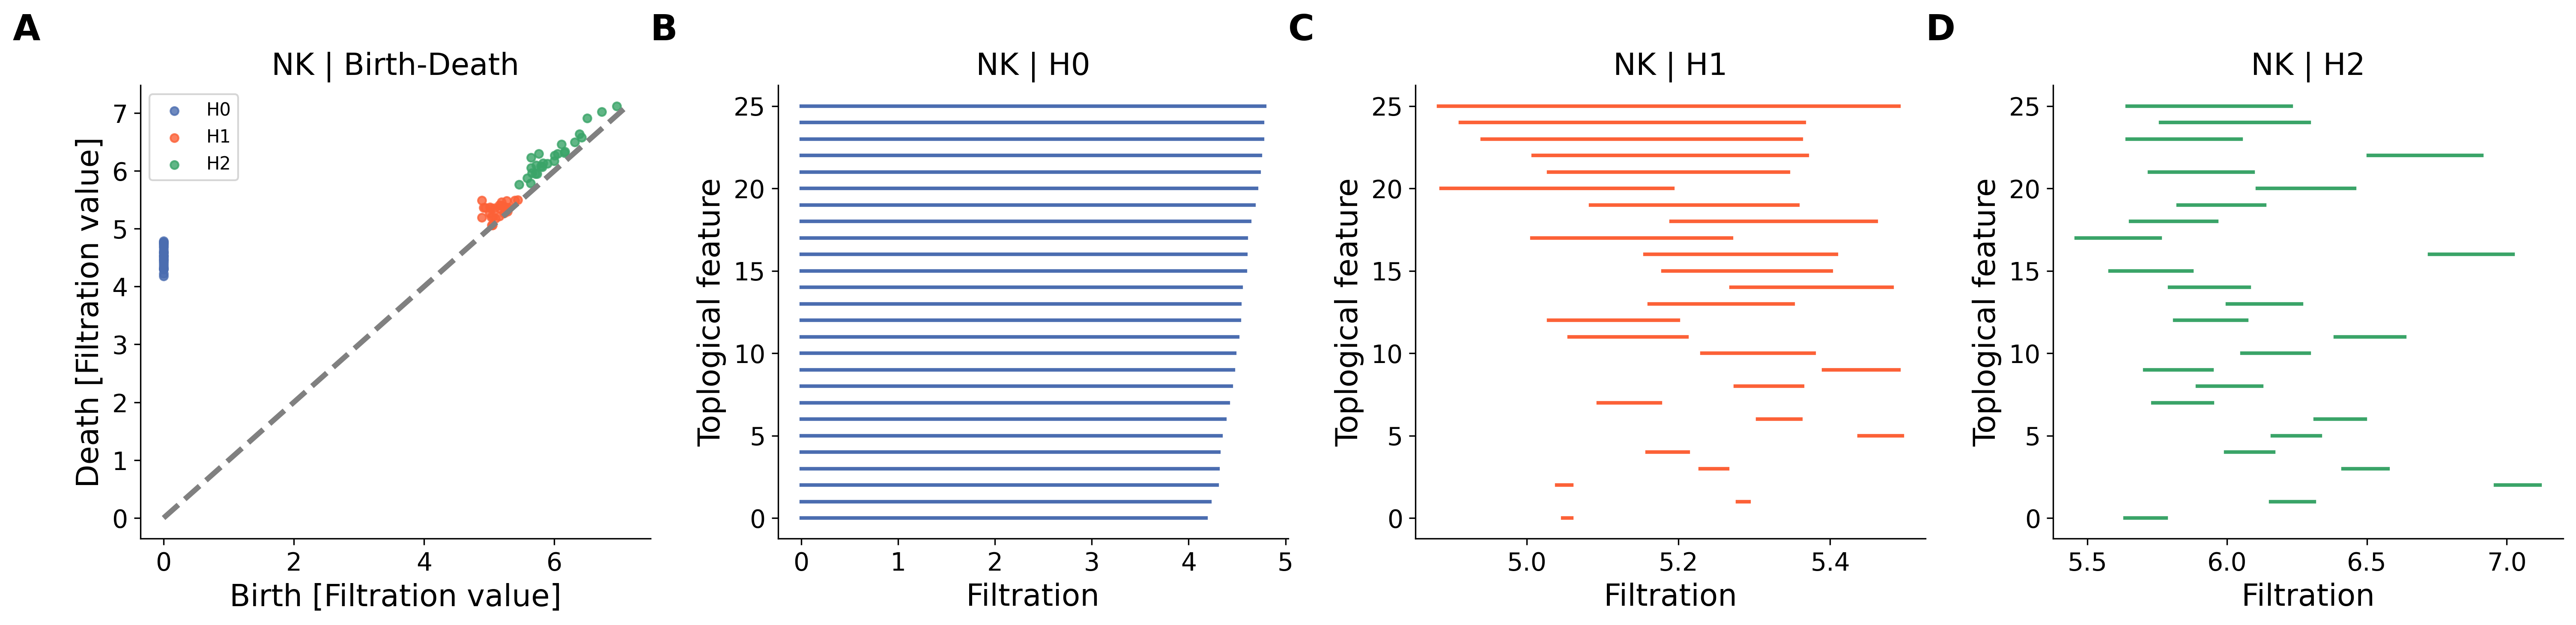

Plotting T


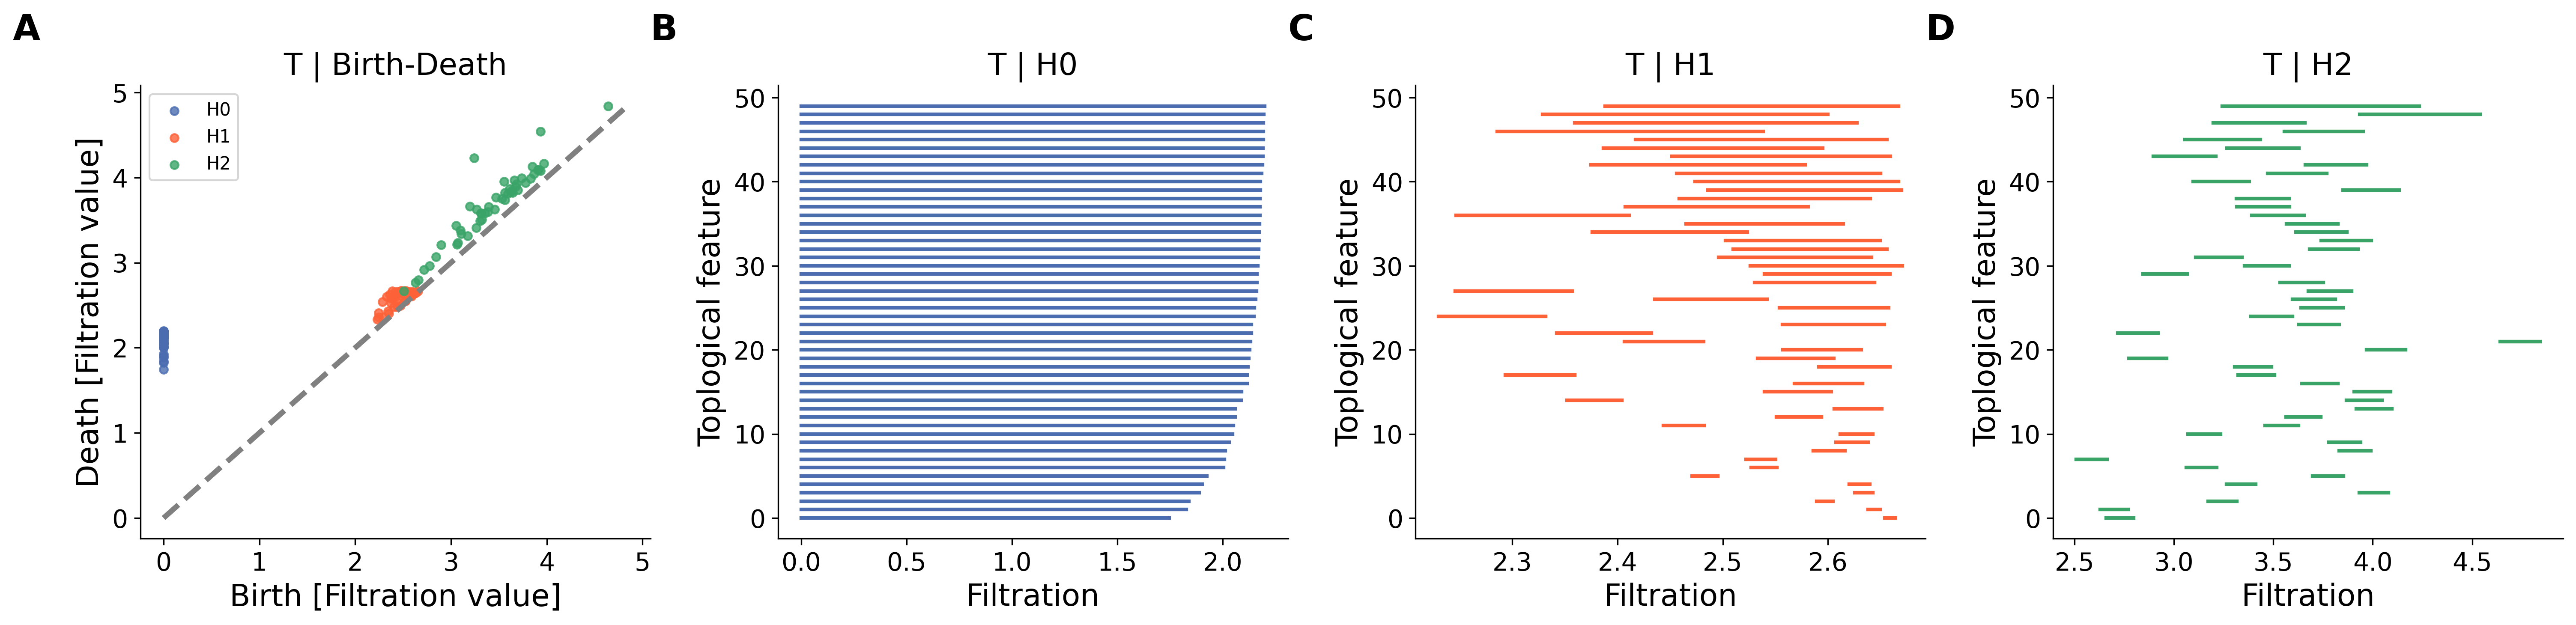

Plotting DC


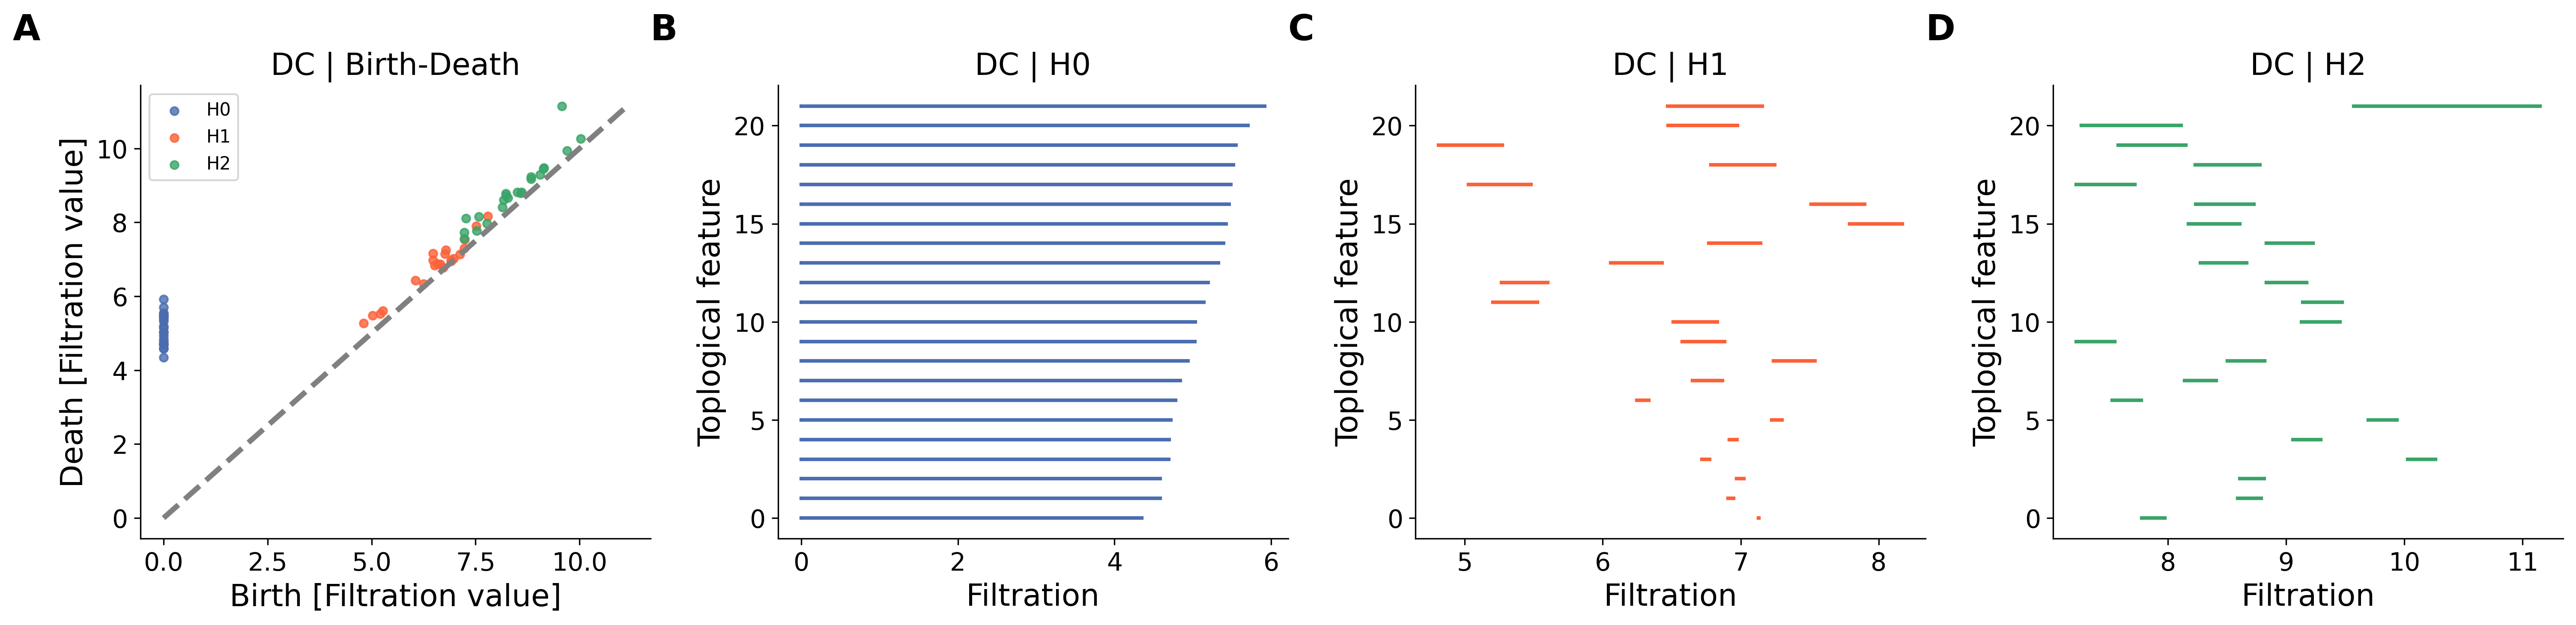

In [18]:
colors=[(0.29226458048518345,0.42830335364029093,0.6916335500700534),
        (0.9893800026041992,0.378955911742755,0.21756841368122667),
        (0.2286247431221609,0.6437632542888629,0.4081322805120583)]    
labels=["H0","H1","H2"]
params = {
    'axes.labelsize': 17,
    'axes.titlesize': 17,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    "lines.linewidth": 3,
    "figure.dpi": 300}
plt.rcParams.update(params)

for celltype in all_results:
    print(f"Plotting {celltype}")

    tda=all_results[celltype]["H2"]["tda"]
    x_tda=all_results[celltype]["H2"]["x_tda"]

    features=[f for f in tda.features[2] if np.isfinite(f["persistence"])]
    features=sorted(features,key=lambda x:x["persistence"],reverse=True)

    n_select=int(np.ceil(0.5*len(features)))
    if hasattr(x_tda,"max_features"): n_select=min(n_select,x_tda.max_features)

    selected_ids=set(f["feature_id"] for f in features[:n_select])

    dgms_plot=[]
    for dim in range(3):
        dgm=tda.dgms[dim]
        feature_ids_dim=set(f["feature_id"] for f in tda.features[dim] if f["feature_id"] in selected_ids)
        keep_idx=[i for i in range(len(dgm)) if i in feature_ids_dim]
        dgms_plot.append(dgm[keep_idx])

    fig,axes=plt.subplots(1,4,figsize=(20,5))

    ax=axes[0]
    max_val=max([np.max(dgm[np.isfinite(dgm[:,1])]) for dgm in dgms_plot if len(dgm)>0 and np.any(np.isfinite(dgm[:,1]))],default=0)

    for dim in range(3):
        dgm=dgms_plot[dim].copy()
        if len(dgm)==0: continue
        dgm[~np.isfinite(dgm[:,1]),1]=max_val
        ax.scatter(dgm[:,0],dgm[:,1],s=20,alpha=0.8,color=colors[dim],label=labels[dim])

    ax.plot([0,max_val],[0,max_val],"--",color="gray")
    ax.set(title=f"{celltype} | Birth-Death", xlabel="Birth [Filtration value]", ylabel="Death [Filtration value]")
    ax.legend()

    for dim in range(3):
        ax=axes[dim+1]
        dgm=dgms_plot[dim].copy()
        if len(dgm)==0: continue

        dgm=dgm[np.argsort(dgm[:,1]-dgm[:,0])]

        for i,(birth,death) in enumerate(dgm):
            if not np.isfinite(death): death=max_val
            ax.plot([birth,death],[i,i],color=colors[dim],lw=2)

        ax.set(title=f"{celltype} | H{dim}", xlabel="Filtration", ylabel="Toplogical feature")

    for l,ax in enumerate(axes): 
        ax.annotate(string.ascii_uppercase[l],xy=(-0.25,1.1),xycoords="axes fraction",fontsize=20,fontweight="bold",ha="left")  
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False) 

    plt.tight_layout()
    plt.savefig(f"Figures/PBMC_Birth_Death_Barplot_{celltype}_GEX.png", format="png", dpi=300, bbox_inches='tight')

    plt.show()

# Violinplots

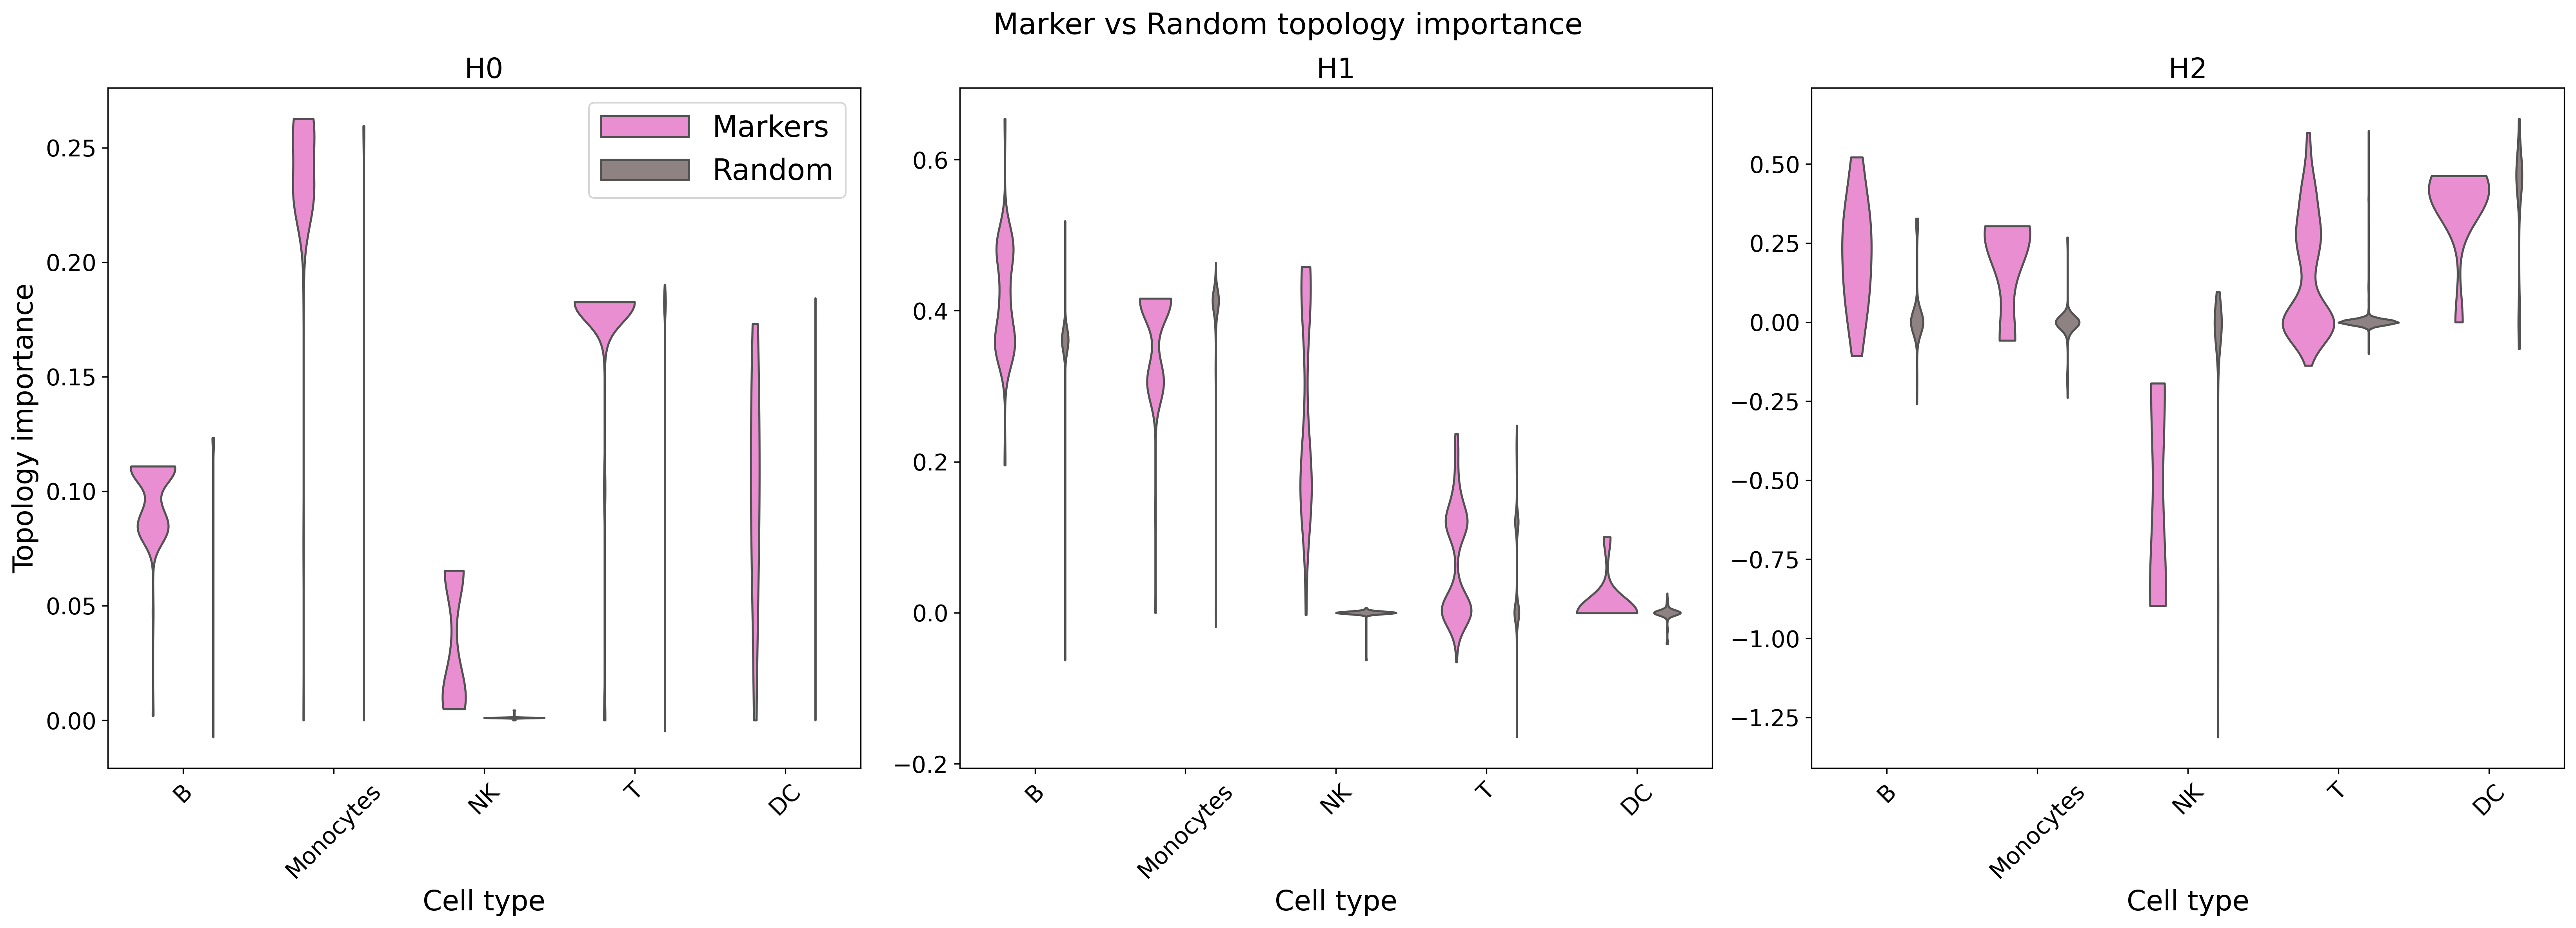

In [25]:
random_color=(0.5665516830630946,0.5037138904751852,0.5075215212500083)
marker_color=(0.9728598314959997,0.5013134514042519,0.8469604310077152)

rows=[]
for celltype in all_results:
    for H in ["H0","H1","H2"]:
        mv=all_results[celltype][H]["marker_vs_random"]
        rows+=[{"celltype":celltype,"H":H,"group":"Markers","score":x} for x in mv["marker_scores"]]
        rows+=[{"celltype":celltype,"H":H,"group":"Random","score":x} for x in mv["random_scores"]]

df=pd.DataFrame(rows)

params = {
    'axes.labelsize': 17,
    'axes.titlesize': 17,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    "lines.linewidth": 3,
    "figure.dpi": 300}
plt.rcParams.update(params)
fig,axes=plt.subplots(1,3,figsize=(22,8))

for l,(ax,H) in enumerate(zip(axes,["H0","H1","H2"])):
    sub=df[df["H"]==H]

    sns.violinplot(data=sub,x="celltype",y="score",hue="group",cut=0,inner=None,ax=ax,palette=[marker_color,random_color])

    for line,color in zip(ax.lines,[marker_color,marker_color,marker_color,random_color,random_color,random_color]*len(sub["celltype"].unique())):
        line.set_color(color)
        line.set_linewidth(2)

    ax.set(title=H,xlabel="Cell type",ylabel="Topology importance" if H=="H0" else "")
    ax.tick_params(axis="x",rotation=45)
    #ax.annotate(string.ascii_uppercase[l],xy=(-0.25,1.1),xycoords="axes fraction",fontsize=20,fontweight="bold",ha="left")

    if H!="H0": ax.get_legend().remove()
        
leg=axes[0].legend(fontsize=18,handlelength=3)

fig.suptitle("Marker vs Random topology importance",fontsize=18)
plt.tight_layout()
plt.savefig(f"Figures/PBMC_Score_Violinplot_GEX.png", format="png", dpi=300, bbox_inches='tight')
plt.show()

# Radar

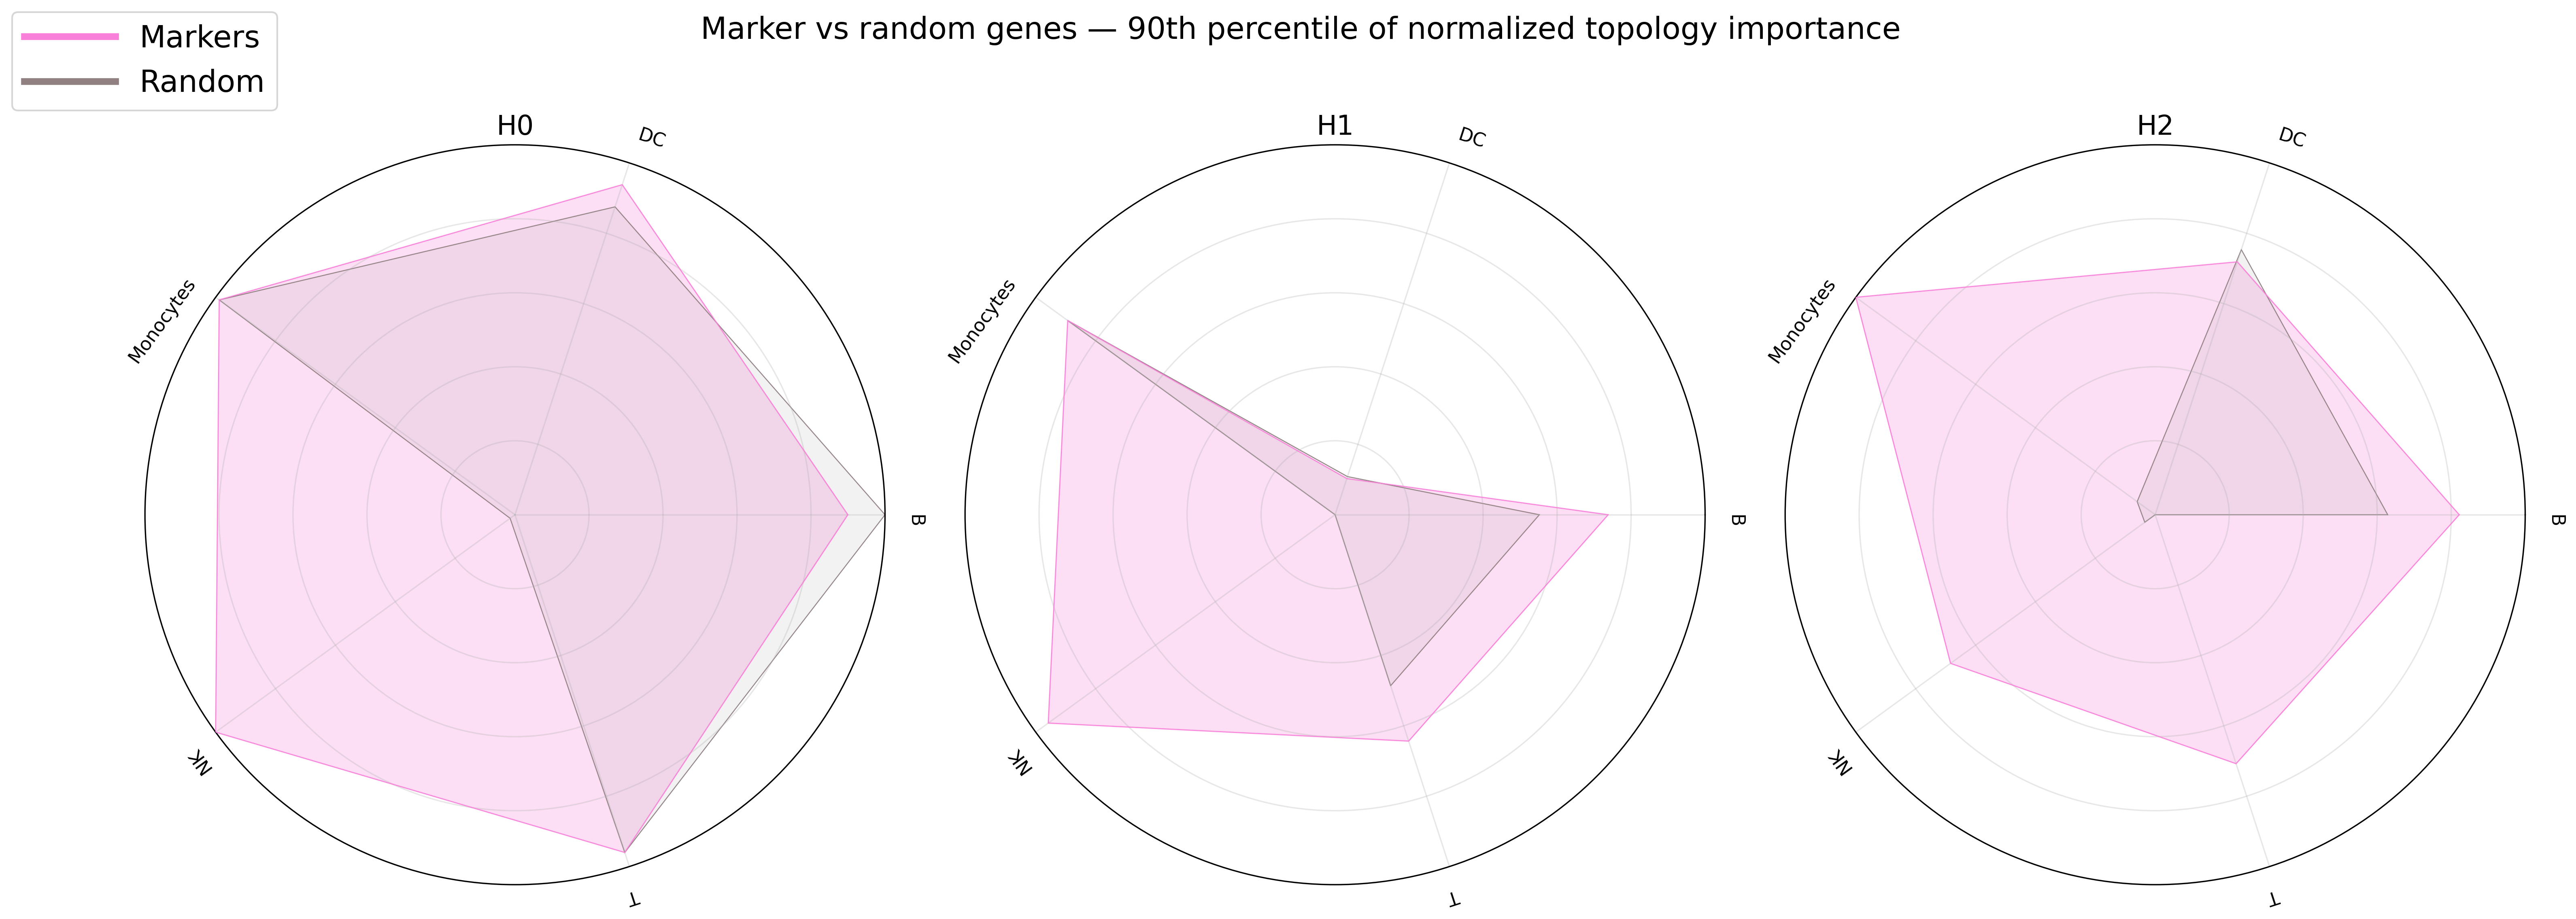

In [23]:
random_color=(0.5665516830630946,0.5037138904751852,0.5075215212500083)
marker_color=(0.9728598314959997,0.5013134514042519,0.8469604310077152)

line_width=0.5
metric="upper_quantile"
threshold=0.5
quantile=90

def compute_metric(x):
    x=np.asarray(x)
    if metric=="mean": return np.mean(x)
    elif metric=="median": return np.median(x)
    elif metric=="fraction_above_threshold": return np.mean(x>threshold)
    elif metric=="upper_quantile": return np.percentile(x,quantile)
    else: raise ValueError(f"Unknown metric: {metric}")

celltypes=sorted(all_results.keys())

n=len(celltypes)
angles=np.linspace(0,2*np.pi,n,endpoint=False)
angles=np.concatenate([angles,[angles[0]]])

params = {
    'axes.labelsize': 17,
    'axes.titlesize': 17,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    "lines.linewidth": 3,
    "figure.dpi": 300}
plt.rcParams.update(params)
fig,axes=plt.subplots(1,3,figsize=(21,8),subplot_kw=dict(polar=True),dpi=300)

for l,(ax,H) in enumerate(zip(axes,["H0","H1","H2"])):

    marker_values=[]
    random_values=[]

    for celltype in celltypes:

        mv=all_results[celltype][H]["marker_vs_random"]

        marker_scores=np.abs(np.asarray(mv["marker_scores"]))
        random_scores=np.abs(np.asarray(mv["random_scores"]))

        all_scores=np.concatenate([marker_scores,random_scores])

        vmin,vmax=all_scores.min(),all_scores.max()

        if vmax==vmin:
            marker_scores_norm=np.zeros_like(marker_scores)
            random_scores_norm=np.zeros_like(random_scores)
        else:
            marker_scores_norm=(marker_scores-vmin)/(vmax-vmin)
            random_scores_norm=(random_scores-vmin)/(vmax-vmin)

        marker_values.append(compute_metric(marker_scores_norm))
        random_values.append(compute_metric(random_scores_norm))

    marker_vals=np.concatenate([marker_values,[marker_values[0]]])
    random_vals=np.concatenate([random_values,[random_values[0]]])

    ax.plot(angles,marker_vals,linewidth=line_width,color=marker_color,label="Markers",zorder=10)
    ax.fill(angles,marker_vals,color=marker_color,alpha=0.25)

    ax.plot(angles,random_vals,linewidth=line_width,color=random_color,label="Random",zorder=1)
    ax.fill(angles,random_vals,color=random_color,alpha=0.10)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([])

    for angle,label in zip(angles[:-1],celltypes):
        angle_deg=np.degrees(angle)
        rotation=angle_deg-90
        ha="right" if 90<=angle_deg<=270 else "left"
        ax.text(angle,1.08,label,rotation=rotation,rotation_mode="anchor",ha=ha,va="center",fontsize=11)

    ax.set_yticklabels([])
    ax.set(title=H)
    ax.title.set_fontsize(16)
    ax.title.set_y(1.05)
    ax.grid(alpha=0.3)
    ax.set_ylim(0,1)

    #ax.annotate(string.ascii_uppercase[l],xy=(-0.15,1.15),xycoords="axes fraction",fontsize=20,fontweight="bold",ha="left")

if metric=="mean": title="Mean normalized topology importance"
elif metric=="median": title="Median normalized topology importance"
elif metric=="fraction_above_threshold": title=f"Fraction of normalized scores > {threshold}"
elif metric=="upper_quantile": title=f"{quantile}th percentile of normalized topology importance"

leg=axes[0].legend(loc="upper left",bbox_to_anchor=(-0.2,1.2),fontsize=18,handlelength=3)
for line in leg.get_lines(): line.set_linewidth(4)
    
fig.suptitle(f"Marker vs random genes — {title}",fontsize=18)

plt.tight_layout()
plt.savefig(f"Figures/PBMC_Score_Radarplot_GEX.png", format="png", dpi=300, bbox_inches='tight')
plt.show()

 # Histogram

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# One figure per cell type
# 3 panels: H0 / H1 / H2
#
# Histograms:
# - marker scores
# - random scores
#
# y-axis:
# probability density
# =====================================================

for celltype in all_results:

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5),
        sharey=True
    )

    fig.suptitle(
        f"{celltype} | Marker vs Random topology importance",
        fontsize=18
    )

    # =================================================
    # H0 / H1 / H2
    # =================================================
    for ax, H in zip(
        axes,
        ["H0", "H1", "H2"]
    ):

        mv = all_results[
            celltype
        ][H][
            "marker_vs_random"
        ]

        marker_scores = np.asarray(
            mv["marker_scores"]
        )

        random_scores = np.asarray(
            mv["random_scores"]
        )

        # ---------------------------------------------
        # Common histogram bins
        # ---------------------------------------------
        xmin = min(
            marker_scores.min(),
            random_scores.min()
        )

        xmax = max(
            marker_scores.max(),
            random_scores.max()
        )

        bins = np.linspace(
            xmin,
            xmax,
            40
        )

        # ---------------------------------------------
        # Random genes
        # ---------------------------------------------
        ax.hist(

            random_scores,

            bins=bins,

            density=True,

            alpha=0.6,

            label="Random"
        )

        # ---------------------------------------------
        # Marker genes
        # ---------------------------------------------
        ax.hist(

            marker_scores,

            bins=bins,

            density=True,

            alpha=0.6,

            label="Markers"
        )

        # ---------------------------------------------
        # Formatting
        # ---------------------------------------------
        ax.set_title(
            H,
            fontsize=15
        )

        ax.set_xlabel(
            "Topology importance"
        )

        if H == "H0":

            ax.set_ylabel(
                "Probability density"
            )

        ax.grid(
            alpha=0.2
        )

        ax.legend()

    plt.tight_layout()

    plt.show()

# Ranking

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
TOP_GENES=500
# =====================================================
# Plot:
# importance vs gene rank
#
# - one figure per cell type
# - 3 panels: H0 / H1 / H2
# - each feature has different color
# - non-marker genes: dots
# - marker genes: X
# =====================================================

for celltype in all_results:

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(21, 6),
    )

    fig.suptitle(
        f"{celltype} | Topology importance rankings",
        fontsize=16
    )

    # =================================================
    # H0 / H1 / H2 panels
    # =================================================
    for h_idx, H in enumerate(["H0", "H1", "H2"]):

        ax = axes[h_idx]

        x_tda = all_results[celltype][H]["x_tda"]

        results = x_tda.results

        marker_idx = set(
            x_tda.marker_idx
        )

        # ---------------------------------------------
        # color map for features
        # ---------------------------------------------
        cmap = plt.cm.get_cmap(
            "tab20",
            len(results)
        )

        # ---------------------------------------------
        # loop over features
        # ---------------------------------------------
        for feature_num, (
            feature_id,
            scores
        ) in enumerate(results.items()):

            scores = np.asarray(scores)

            # -----------------------------------------
            # rank genes by importance
            # -----------------------------------------
            order = np.argsort(scores)[::-1]
            order = order[:TOP_GENES]

            ranked_scores = scores[order]

            ranks = np.arange(
                len(order)
            )

            # -----------------------------------------
            # identify markers
            # -----------------------------------------
            marker_mask = np.array([

                g in marker_idx

                for g in order

            ])

            non_marker_mask = ~marker_mask

            color = cmap(feature_num)

            # -----------------------------------------
            # non-marker genes
            # -----------------------------------------
            ax.scatter(

                ranks[non_marker_mask],

                ranked_scores[
                    non_marker_mask
                ],

                s=1,
                zorder=1,
                alpha=0.5,

                color=color
            )

            # -----------------------------------------
            # marker genes
            # -----------------------------------------
            ax.scatter(

                ranks[marker_mask],

                ranked_scores[
                    marker_mask
                ],

                marker="x",
                zorder=10,
                s=150,

                linewidths=2,

                color=color
            )

        # ---------------------------------------------
        # panel formatting
        # ---------------------------------------------
        ax.set_title(H)

        ax.set_xlabel(
            "Gene rank"
        )

        if h_idx == 0:

            ax.set_ylabel(
                "Importance"
            )


    plt.tight_layout()

    plt.show()

# Global

In [4]:
marker_genes_by_celltype = {
    'T': [
        'IL7R', 'TRAC', 'GATA3',
        'LEF1', 'FHIT', 'RORA', 'ITGB1',
        'CD8A', 'CD8B', 'CD248', 'CCL5',
        'GZMH', 'GZMK',
        'KLRB1', 'SLC4A10',
        'IL32'
    ],

    'NK': [
        'GNLY', 'NKG7',
        'IL32'
    ],

    'B': [
        'CD79A', 'MS4A1', 'IGHD', 'IGHM',
        'IL4R', 'TNFRSF13C'
    ],

    'Monocytes': [
        'KLF4', 'LYZ', 'S100A8', 'ITGAM', 'CD14',
        'DPYD',
        'FCGR3A', 'MS4A7', 'CST3'
    ],

    'DC': [
        'CLEC10A', 'IRF8', 'TCF4'
    ]
}

In [5]:
global_results = {}

for celltype in marker_genes_by_celltype:

    global_results[celltype] = load(
        f"Datasets/PBMC/TDA_CellType/{celltype}/Global/"
        f"{celltype}_global_summary.joblib"
    )

print(f"Loaded {len(global_results)} cell types")

FileNotFoundError: [Errno 2] No such file or directory: 'Datasets/PBMC/TDA_CellType/T/Global/T_global_summary.joblib'